## Student Dropout Risk

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mutual_info_score, auc, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

### Data Cleaning And Preparation

In [2]:
def clean_and_normalize_raw_data(df: pd.DataFrame):
    df = df.copy()
    df.columns = df.columns.str.lower().str.replace(' ', '_')
    categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
    numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)

    for column in categorical_columns:
        df[column] = df[column].str.lower().str.replace(' ', '_')
        df[column] = df[column].fillna("NA")

    for column in numerical_columns:
        df[column] = df[column].fillna(0.0)

    return df

In [3]:
df_raw = pd.read_csv('./data/student_dropout_risk_2026.csv')
print('Shape', df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame('dtype'))
print('Missing values:', int(df_raw.isna().sum().sum()))
print('Duplicate rows:', int(df_raw.duplicated().sum()))

Shape (100000, 34)


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


,dtype
person_id,int64
age,int64
gender,str
nationality,str
first_generation,int64
disability_status,int64
family_income_level,str
scholarship_holder,int64
tuition_up_to_date,int64
part_time_job,int64


Missing values: 0
Duplicate rows: 0


> The dataset appears to be clean, with no missing values or apparent formatting inconsistencies.

In [4]:
df_normalized = clean_and_normalize_raw_data(df_raw)

> Field person_id will be excluded from the dataset because it's and identifier and is not relevant for the model training

In [5]:
del df_normalized['person_id']

In [6]:
df_normalized.head(1)

,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,23,male,brazil,0,0,low,1,0,1,24,...,4,16.3,0,3,8,0,6,37,5.7,0


## Exploratory Data Analysis (EDA)

In [7]:
print('Target Counts:')
display(df_normalized['dropout'].value_counts().to_frame('count'))
print('Target rate: ', round(df_normalized['dropout'].mean(), 4))
display(df_normalized.describe(include='all').T)

Target Counts:


,count
dropout,
0,67996
1,32004


Target rate:  0.32


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,100000.0,NaN,NaN,NaN,21.52084,3.399468,15.0,19.0,21.0,24.0,30.0
gender,100000,3,female,50731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nationality,100000,15,usa,29979,NaN,NaN,NaN,NaN,NaN,NaN,NaN
first_generation,100000.0,NaN,NaN,NaN,0.42013,0.493582,0.0,0.0,0.0,1.0,1.0
disability_status,100000.0,NaN,NaN,NaN,0.20877,0.406432,0.0,0.0,0.0,0.0,1.0
family_income_level,100000,3,middle,40213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scholarship_holder,100000.0,NaN,NaN,NaN,0.5897,0.491891,0.0,0.0,1.0,1.0,1.0
tuition_up_to_date,100000.0,NaN,NaN,NaN,0.78486,0.410921,0.0,1.0,1.0,1.0,1.0
part_time_job,100000.0,NaN,NaN,NaN,0.48192,0.499676,0.0,0.0,0.0,1.0,1.0
weekly_work_hours,100000.0,NaN,NaN,NaN,8.74462,10.232842,0.0,0.0,0.0,18.0,40.0


## Validation Framework

In [8]:
df_full_train, df_test = train_test_split(df_normalized, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.dropout.values
y_val = df_val.dropout.values
y_test = df_test.dropout.values

del df_train['dropout']
del df_val['dropout']
del df_test['dropout']

df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train.dropout.values



> Categorical and numerical variables 

In [16]:
categorical = list(df_train.dtypes[df_train.dtypes == 'str'].index)
numerical = list(df_train.dtypes[df_train.dtypes != 'str'].index)

## Feature Importance

In [17]:
def mutual_info_dropout_score(series):
    return mutual_info_score(series, df_full_train.dropout)

global_dropout = df_full_train.dropout.mean()

print('\n Dropout Risk and ratio \n')
print(f'\n Global dropout value: {global_dropout} \n')
print('\n Differences and risks for every categorical variable \n')

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).dropout.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_dropout
    df_group['risk'] = df_group['mean'] / global_dropout
    display(df_group)
    print()
    print()

mi = round(df_full_train[categorical].apply(mutual_info_dropout_score),2)

print('\n Mutual information \n')
print(mi.sort_values(ascending=False))

ncorr = df_full_train[numerical].corrwith(df_full_train.dropout).sort_values(ascending=False)

print('\n Numerical correlations \n')
print(ncorr)


 Dropout Risk and ratio 


 Global dropout value: 0.3196 


 Differences and risks for every categorical variable 

gender


,mean,count,diff,risk
gender,,,,
female,0.318911,40494,-0.000689,0.997846
male,0.319637,37868,0.000037,1.000115
other,0.335775,1638,0.016175,1.050611




nationality


,mean,count,diff,risk
nationality,,,,
australia,0.325490,765,0.005890,1.018430
brazil,0.317566,5539,-0.002034,0.993637
canada,0.300185,1619,-0.019415,0.939253
china,0.325059,8057,0.005459,1.017081
egypt,0.309389,1587,-0.010211,0.968050
germany,0.329087,3297,0.009487,1.029684
india,0.320059,9542,0.000459,1.001435
indonesia,0.330089,2363,0.010489,1.032819
mexico,0.306281,4904,-0.013319,0.958325




family_income_level


,mean,count,diff,risk
family_income_level,,,,
high,0.198777,20113,-0.120823,0.621955
low,0.429860,27723,0.110260,1.344993
middle,0.300118,32164,-0.019482,0.939043




course_type


,mean,count,diff,risk
course_type,,,,
arts_&_humanities,0.318194,14400,-0.001406,0.995602
business,0.320531,19970,0.000931,1.002912
health_sciences,0.322540,11952,0.002940,1.009200
law_&_social_sciences,0.316881,9502,-0.002719,0.991491
stem,0.319284,24176,-0.000316,0.999010




study_mode


,mean,count,diff,risk
study_mode,,,,
full-time,0.318713,52141,-0.000887,0.997224
online,0.293154,10312,-0.026446,0.917252
part-time,0.337779,17547,0.018179,1.056879





 Mutual information 

family_income_level    0.02
gender                 0.00
nationality            0.00
course_type            0.00
study_mode             0.00
dtype: float64

 Numerical correlations 

units_failed                    0.464230
missed_deadlines                0.281928
weekly_work_hours               0.179156
part_time_job                   0.159176
stress_level                    0.131967
first_generation                0.098455
disability_status               0.052374
mental_health_support           0.026921
units_enrolled                  0.018279
commute_time_mins               0.004803
international_student           0.001417
age                             0.000049
scholarship_holder             -0.022428
previous_qualification_grade   -0.030983
semester                       -0.031436
sleep_hours                    -0.056254
extracurricular_activities     -0.077646
satisfaction_score             -0.084944
admission_grade                -0.129204
tuition_up_to_

## Logistic Regression Model

In [25]:
def logistic_training(df_to_train, y_to_train, features, regularization=1.0):
    dv = DictVectorizer(sparse=False)
    train_dict = df_to_train[features].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(solver='liblinear', C=regularization, max_iter=1000)
    model.fit(X_train, y_to_train)
    
    return dv, model

In [26]:
def predict(df, dv, model, features):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [27]:
features = categorical + numerical

In [29]:
dv, model = logistic_training(df_train, y_train, features)
y_predict = predict(df_val, dv, model, features)

decision = (y_predict >= 0.5)
original_accuracy = (y_val == decision).mean()
original_accuracy

np.float64(0.83935)

In [30]:
for feature in features:
    selected_features = [col for col in features if col != feature]

    dv, model = logistic_training(df_train, y_train, selected_features)
    y_predict = predict(df_val, dv, model, selected_features)
    decision = (y_predict >= 0.5)

    accuracy = (y_val == decision).mean()
    diff = original_accuracy - accuracy
    print(f'{feature}: accuracy={accuracy:.6f}, diff={diff:.6f}')



gender: accuracy=0.839200, diff=0.000150
nationality: accuracy=0.839150, diff=0.000200
family_income_level: accuracy=0.838000, diff=0.001350
course_type: accuracy=0.839450, diff=-0.000100
study_mode: accuracy=0.840200, diff=-0.000850
age: accuracy=0.839550, diff=-0.000200
first_generation: accuracy=0.839150, diff=0.000200
disability_status: accuracy=0.839750, diff=-0.000400
scholarship_holder: accuracy=0.837850, diff=0.001500
tuition_up_to_date: accuracy=0.835350, diff=0.004000
part_time_job: accuracy=0.839550, diff=-0.000200
weekly_work_hours: accuracy=0.838700, diff=0.000650
semester: accuracy=0.839300, diff=0.000050
international_student: accuracy=0.839250, diff=0.000100
admission_grade: accuracy=0.838900, diff=0.000450
previous_qualification_grade: accuracy=0.839250, diff=0.000100
units_enrolled: accuracy=0.839400, diff=-0.000050
units_passed: accuracy=0.839300, diff=0.000050
units_failed: accuracy=0.839250, diff=0.000100
gpa_semester_1: accuracy=0.834100, diff=0.005250
gpa_semeste

In [34]:
regularization_values = [0.000001, 0.00001, 0.0001, 0.001, 0.1, 1, 10, 100]

In [35]:
for option in regularization_values:
    dv, model = logistic_training(df_train, y_train, features, option)
    y_predict = predict(df_val, dv, model, features)
    decision = (y_predict >= 0.5)

    accuracy = (y_val == decision).mean()
    accuracy = round(accuracy,3)
    print(f'{option}: accuracy={accuracy}')



1e-06: accuracy=0.725
1e-05: accuracy=0.79
0.0001: accuracy=0.815
0.001: accuracy=0.829
0.1: accuracy=0.84
1: accuracy=0.839
10: accuracy=0.839
100: accuracy=0.839


### AUC for numerical features

In [36]:
scores = {}
for feature in numerical:
    score = roc_auc_score(y_train, df_train[feature])

    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])

    scores[feature] = score

print(scores)

{'age': 0.5028475878512242, 'first_generation': 0.5527260397470775, 'disability_status': 0.5229280090038184, 'scholarship_holder': 0.5103986471915629, 'tuition_up_to_date': 0.5589160023741816, 'part_time_job': 0.5852797747596079, 'weekly_work_hours': 0.6021043188877471, 'semester': 0.5191903930562545, 'international_student': 0.5001792221323439, 'admission_grade': 0.5776628711071975, 'previous_qualification_grade': 0.5168772091235865, 'units_enrolled': 0.5095039465732956, 'units_passed': 0.6600535758376209, 'units_failed': 0.7790348501431252, 'gpa_semester_1': 0.8503431360501804, 'gpa_semester_2': 0.8241044240647496, 'attendance_rate': 0.6726813608501724, 'assignments_submitted_rate': 0.6678967646911238, 'library_visits_per_month': 0.6697062086881571, 'lms_logins_per_week': 0.625656705586386, 'extracurricular_activities': 0.5426275418501758, 'missed_deadlines': 0.698529762991291, 'stress_level': 0.5802642145030208, 'mental_health_support': 0.5129235773239418, 'satisfaction_score': 0.55

### Precision And Recall

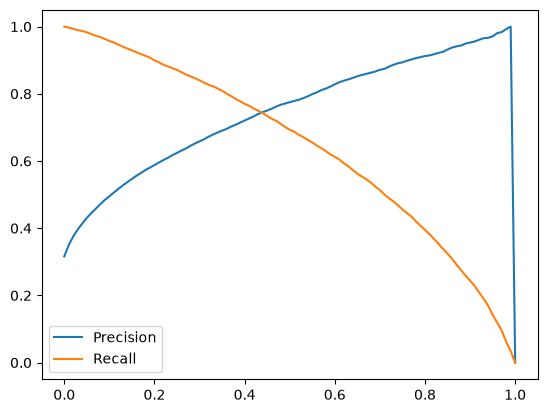

In [37]:
thresholds = np.arange(0, 1.01, 0.01)

scores = []

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

dv, model = logistic_training(df_train, y_train, features)
y_predict = predict(df_val, dv, model, features)

for t in thresholds:
    predict_positive = (y_predict >= t)
    predict_negative = (y_predict < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append((t, p, r))

columns = ['threshold', 'precision', 'recall']
df_pr = pd.DataFrame(scores, columns = columns)

plt.plot(df_pr.threshold, df_pr['precision'], label='Precision')
plt.plot(df_pr.threshold, df_pr['recall'], label='Recall')
plt.legend()

In [38]:
df_pr['diff'] = abs(df_pr.precision - df_pr.recall)
df_filtered = df_pr[(df_pr.precision != 0) | (df_pr.recall != 0)]
df_filtered.sort_values('diff').head()

,threshold,precision,recall,diff
44,0.44,0.745316,0.742604,0.002712
43,0.43,0.739931,0.749881,0.009950
45,0.45,0.750121,0.734219,0.015902
42,0.42,0.732638,0.756051,0.023413
46,0.46,0.755724,0.725835,0.029889


In [39]:
df_pr['f1'] = (2*((df_pr.precision * df_pr.recall)/(df_pr.precision + df_pr.recall))).fillna(0)
df_pr.sort_values('f1', ascending=False).head()

,threshold,precision,recall,diff,f1
41,0.41,0.726794,0.764278,0.037484,0.745065
35,0.35,0.690479,0.808891,0.118412,0.745009
43,0.43,0.739931,0.749881,0.009950,0.744873
37,0.37,0.702411,0.792754,0.090343,0.744853
39,0.39,0.714161,0.777883,0.063722,0.744662


### Fold

In [48]:
def kflod_eva(splits, regularizations=[1.0]):
    for regularization in regularizations:
        kflod = KFold(n_splits=splits, shuffle=True, random_state=1)
        scores = []

        for train_idx, val_idx in kflod.split(df_full_train):
            df_to_train = df_full_train.iloc[train_idx]
            df_to_val = df_full_train.iloc[val_idx]

            y_to_train = df_to_train.dropout.values
            y_to_val = df_to_val.dropout.values

            dv, model = logistic_training(df_to_train, y_to_train, features, regularization=regularization)
            y_pred = predict(df_to_val, dv, model, features)

            auc = roc_auc_score(y_to_val, y_pred)
            scores.append(auc)

        print('C=%s %.3f +- %.3f' % (regularization, np.mean(scores), np.std(scores)))

In [49]:
kflod_eva(splits=5)

C=1.0 0.903 +- 0.003


In [51]:
kflod_eva(splits=5,regularizations=[0.000001, 0.001, 0.1, 1, 10, 100])

C=1e-06 0.775 +- 0.005
C=0.001 0.894 +- 0.003
C=0.1 0.903 +- 0.003
C=1 0.903 +- 0.003
C=10 0.903 +- 0.003
C=100 0.903 +- 0.003


## Final model setup

The final model uses Logistic Regression to estimate the probability of student dropout (dropout = 1). The configuration below was selected using training and validation data, before evaluating the held-out test set.

Regularization (C = 1.0). A 5-fold cross-validation was performed on df_full_train using several regularization strengths. Very small values of C produced lower ROC-AUC scores (0.775 at C = 0.000001 and 0.894 at C = 0.001). ROC-AUC stabilized at approximately 0.903 for values from 0.1 to 100, with a standard deviation of approximately 0.003. Therefore, C = 1.0 was selected as a simple, well-performing default. In scikit-learn, smaller C means stronger regularization. These scores are rounded, so they do not prove C = 1.0 is uniquely optimal.

Prediction threshold (0.41). Logistic Regression returns a dropout probability, which must be converted into a yes/no prediction. The default cutoff is often 0.50, but the validation-set analysis evaluated thresholds from 0 to 1 and found that 0.41 achieved the highest observed F1-score (0.7451) among those tested. At this threshold, validation precision was 0.7268 and recall was 0.7643. It was chosen to balance precision and recall based on validation results, not on the test set. The threshold controls classification decisions; it does not change ROC-AUC, which is calculated from probabilities.

Training configuration. The features list includes the categorical and numerical predictor columns selected earlier. DictVectorizer(sparse=False) converts records into numeric vectors and encodes categorical features; it is fitted during training and reused during prediction. solver='liblinear' is the optimizer used by Logistic Regression, and max_iter=1000 allows up to 1,000 optimization iterations if needed for convergence. These two settings were kept fixed rather than tuned.

Final training and evaluation. The final model is refitted on df_full_train (80% of the dataset), while df_test (20%) remains untouched until the final evaluation. Accuracy, precision, recall, and F1-score are calculated from binary predictions at the chosen threshold of 0.41. ROC-AUC is calculated from the predicted probabilities. The test results must be treated as the final estimate of generalization performance, not used for additional parameter or threshold tuning.

In [52]:
final_dv, final_model = logistic_training(df_full_train, y_full_train, features, regularization=1.0)

In [53]:
y_pred = predict(df_test, final_dv, final_model, features)

threshold = 0.41
decision = y_pred >= threshold

In [56]:
print(f"Accuracy: {accuracy_score(y_test, decision):.4f}")
print(f"Precision: {precision_score(y_test, decision):.4f}")
print(f"Recall: {recall_score(y_test, decision):.4f}")
print(f"F1-Score: {f1_score(y_test, decision):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred):.4f}")

Accuracy: 0.8344
Precision: 0.7299
Recall: 0.7704
F1-Score: 0.7496
ROC-AUC: 0.9056
